# Interpretabilidad de los modelos

Los modelos más precisos, como los ensambles de árboles o las redes neuronales, suelen ser cajas negras: no hay una ecuación que muestre cómo cada variable afecta la predicción. En geociencias eso es un problema, porque necesitamos verificar que el modelo aprendió relaciones físicamente plausibles y no correlaciones espurias, y porque sus resultados alimentan decisiones de ordenamiento del territorio o de gestión del riesgo que hay que justificar. Las técnicas de interpretabilidad agnósticas al modelo abren esas cajas negras {cite}`molnar2022`.

Se usa un inventario sintético con una relación no lineal conocida, para poder comparar lo que dice cada técnica con la verdad: la probabilidad de deslizamiento crece con la pendiente con un umbral cerca de 30°, disminuye con la distancia a los cauces, aumenta con la lluvia solo en pendientes fuertes, y hay una variable de ruido.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import roc_auc_score
plt.rcParams['figure.dpi'] = 100
rng = np.random.default_rng(14)

n = 4000
pend = rng.gamma(4, 6, n); dist = rng.exponential(250, n); lluv = rng.normal(2500, 500, n); ruido = rng.normal(0, 1, n)
eta = -3 + 3 / (1 + np.exp(-(pend - 30) / 3)) - 0.004 * dist + 0.002 * (lluv - 2500) * (pend > 25)
y = (rng.random(n) < 1 / (1 + np.exp(-eta))).astype(int)
X = np.column_stack([pend, dist, lluv, ruido]); nombres = ['pendiente', 'dist_cauce', 'lluvia', 'ruido']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
gb = GradientBoostingClassifier(n_estimators=250, learning_rate=0.05, max_depth=2, min_samples_leaf=40, subsample=0.8, random_state=0).fit(X_tr, y_tr)
print(f'AUC en prueba: {roc_auc_score(y_te, gb.predict_proba(X_te)[:, 1]):.3f}')

AUC en prueba: 0.853


## Importancia por permutación

La importancia por permutación de una variable es cuánto empeora el desempeño del modelo, en datos de prueba, cuando se desordenan al azar los valores de esa variable, rompiendo su relación con la respuesta. Si el modelo no usa la variable, desordenarla no cambia nada. Es agnóstica al modelo y se interpreta en las unidades de la métrica. Su principal limitación aparece con variables correlacionadas: al permutar una, el modelo puede apoyarse en la otra, y ambas parecen menos importantes de lo que son.

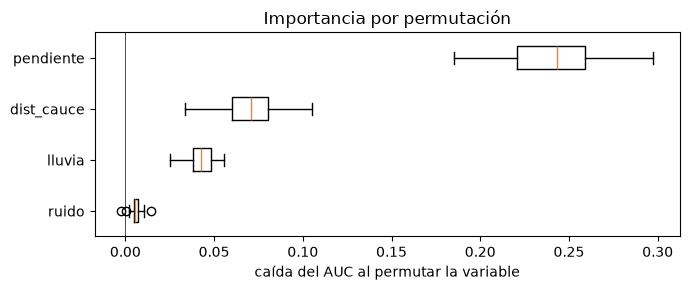

In [2]:
pi = permutation_importance(gb, X_te, y_te, scoring='roc_auc', n_repeats=20, random_state=0)
orden = np.argsort(pi.importances_mean)
fig, ax = plt.subplots(figsize=(7, 3))
ax.boxplot(pi.importances[orden].T, orientation='horizontal', tick_labels=np.array(nombres)[orden])
ax.axvline(0, color='k', lw=0.5); ax.set_xlabel('caída del AUC al permutar la variable'); ax.set_title('Importancia por permutación')
plt.tight_layout(); plt.show()

## Dependencia parcial y efectos individuales

La gráfica de dependencia parcial (PDP) muestra el efecto promedio de una variable sobre la predicción: para cada valor de la variable, se fija ese valor en todas las observaciones y se promedian las predicciones. Las curvas de expectativa condicional individual (ICE) muestran el mismo cálculo para cada observación por separado; si las curvas tienen formas distintas, hay interacciones que el promedio esconde. Una PDP de dos variables muestra directamente su interacción.

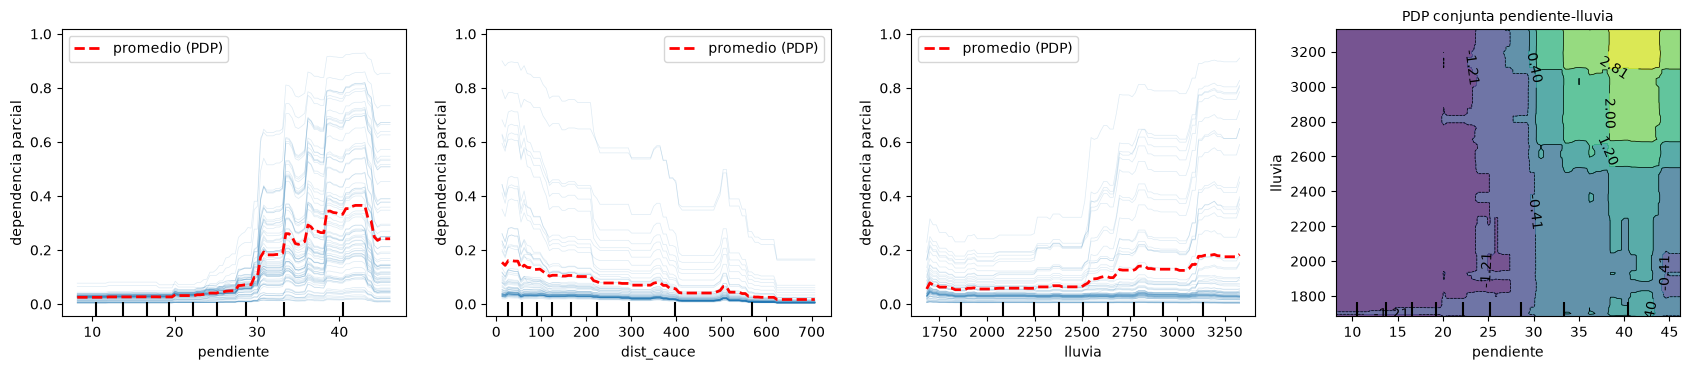

In [3]:
fig, axs = plt.subplots(1, 4, figsize=(17, 3.8))
PartialDependenceDisplay.from_estimator(gb, X_tr, [0, 1, 2], feature_names=nombres, kind='both', subsample=80,
                                        random_state=0, ax=axs[:3], ice_lines_kw={'alpha': 0.15}, pd_line_kw={'color': 'r', 'lw': 2, 'label': 'promedio (PDP)'})
PartialDependenceDisplay.from_estimator(gb, X_tr, [(0, 2)], feature_names=nombres, ax=axs[3], contour_kw={'cmap': 'viridis'})
for a in fig.axes:
    if a.get_ylabel() == 'Partial dependence':
        a.set_ylabel('dependencia parcial')
fig.axes[-1].set_title('PDP conjunta pendiente-lluvia', fontsize=10)
plt.tight_layout(); plt.show()

El modelo recuperó el umbral de pendiente cercano a 30°, el efecto decreciente de la distancia al cauce y la interacción entre pendiente y lluvia: las curvas ICE de la lluvia se separan en dos familias, planas para las celdas de baja pendiente y crecientes para las de alta pendiente, y la PDP bidimensional muestra que la lluvia solo importa por encima de unos 25°.

## Valores de Shapley (SHAP)

Los valores SHAP {cite}`lundberg2017` reparten la predicción de cada observación entre las variables, usando los valores de Shapley de la teoría de juegos cooperativos: la contribución de una variable es su aporte marginal promedio a la predicción sobre todos los posibles órdenes en que pueden "entrar" las variables. Tienen propiedades deseables: las contribuciones suman exactamente la diferencia entre la predicción y el valor promedio, y una variable que no se usa recibe cero. Permiten explicaciones locales (por qué esta celda tiene alta susceptibilidad) y, al agregarlas, globales (gráficos de resumen o de dependencia). La librería `shap` tiene algoritmos eficientes para árboles; la celda siguiente calcula valores de Shapley exactos para una observación, por enumeración de los subconjuntos, para mostrar el concepto. El valor de un subconjunto de variables se aproxima fijando esas variables en el valor de la observación y promediando la predicción sobre los datos de fondo para las demás.

Observación: pendiente 42.2°, distancia 64 m, lluvia 3705 mm, ruido -0.26
Valor base (predicción media) 0.091 + suma de contribuciones 0.864 = 0.955; predicción del modelo 0.955


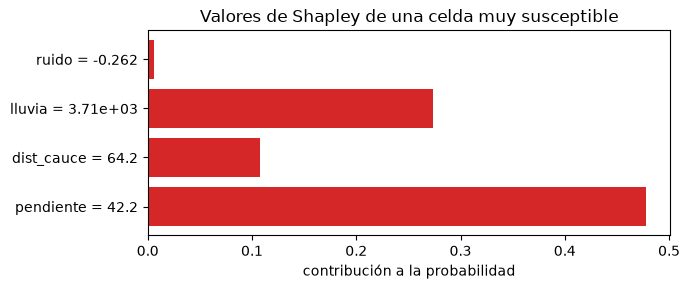

In [4]:
from itertools import combinations
from math import factorial
fondo = X_tr[rng.choice(len(X_tr), 300, replace=False)]
def valor(x, S):
    Z = fondo.copy(); Z[:, list(S)] = x[list(S)]
    return gb.predict_proba(Z)[:, 1].mean()
def shapley(x):
    p = len(x); phi = np.zeros(p)
    for j in range(p):
        otros = [k for k in range(p) if k != j]
        for r in range(p):
            for S in combinations(otros, r):
                w = factorial(len(S)) * factorial(p - len(S) - 1) / factorial(p)
                phi[j] += w * (valor(x, S + (j,)) - valor(x, S))
    return phi

i = np.argmax(gb.predict_proba(X_te)[:, 1])            # la celda más susceptible del conjunto de prueba
x = X_te[i]; phi = shapley(x); base = valor(x, ())
print(f'Observación: pendiente {x[0]:.1f}°, distancia {x[1]:.0f} m, lluvia {x[2]:.0f} mm, ruido {x[3]:.2f}')
print(f'Valor base (predicción media) {base:.3f} + suma de contribuciones {phi.sum():.3f} = {base + phi.sum():.3f}; predicción del modelo {valor(x, (0, 1, 2, 3)):.3f}')
fig, ax = plt.subplots(figsize=(7, 3))
cols = ['tab:red' if v > 0 else 'tab:blue' for v in phi]
ax.barh([f'{nm} = {v:.3g}' for nm, v in zip(nombres, x)], phi, color=cols); ax.axvline(0, color='k', lw=0.5)
ax.set_xlabel('contribución a la probabilidad'); ax.set_title('Valores de Shapley de una celda muy susceptible')
plt.tight_layout(); plt.show()

## Cautelas

Las técnicas de interpretabilidad explican el modelo, no la naturaleza. Si el modelo aprendió una correlación espuria, la explicación la mostrará con toda claridad, pero no la volverá causal. Con variables correlacionadas, la dependencia parcial y la permutación evalúan combinaciones de valores que no existen en los datos, y pueden dar resultados engañosos; los gráficos de efectos locales acumulados (ALE) atenúan ese problema. Por eso las explicaciones deben contrastarse siempre con el conocimiento físico del proceso, que es la verdadera prueba de un modelo en geociencias.

## Para profundizar

{cite:t}`molnar2022` es una guía completa y gratuita de los métodos de interpretabilidad. {cite:t}`lundberg2017` presentan SHAP. El notebook 25 del curso aplica la librería `shap` con gráficos de resumen, cascada y fuerza.